# Results and Evaluation

In [1]:
# imports and paths 
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error, 
    accuracy_score, 
    f1_score, 
    roc_auc_score, 
    roc_curve, 
    confusion_matrix
)

ROOT = Path.cwd().resolve()
if not (ROOT / "presentation_material").exists():
    ROOT = ROOT.parent
    
sys.path.insert(0, str(ROOT))

# locate outputs
TASK1_DIR = ROOT / "presentation_material" / "task1" / "predictions"
TASK2_DIR = ROOT / "presentation_material" / "task2" / "predictions"

# Save figures and summary tables here.
RESULTS_DIR = ROOT / "presentation_material" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Task 1 results
Comparison and evaluation of classical models (logistic regression, random forest) and the deep learning model (1D-CNN) against the majority baseline. 

In [2]:
# load predictions
task1_models = {
    "Majority baseline": "majority_baseline",
    "Logistic regression": "logistic_regression",
    "Random forest": "random_forest",
    "1D-CNN": "cnn_1d",
    "Logistic regression (tuned)": "logistic_regression_tuned",
    "Random forest (tuned)": "random_forest_tuned",
    "1D-CNN (tuned)": "cnn_1d_tuned",
}

task1_predictions = {}
for model_name, prefix in task1_models.items():
    paths = [TASK1_DIR / f"{prefix}_val_fold{k}.csv" for k in range(1, 6)]
    if all(p.exists() for p in paths):                      # skip models that have not been run
        task1_predictions[model_name] = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True)
print(list(task1_predictions))

['Majority baseline', 'Logistic regression', 'Random forest', '1D-CNN', 'Logistic regression (tuned)', 'Random forest (tuned)', '1D-CNN (tuned)']


In [3]:
task1_results = []
for model_name, df in task1_predictions.items():
    fold_auc = [roc_auc_score(g.y_true, g.y_prob) for _, g in df.groupby("fold")]
    task1_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(df.y_true, df.y_pred),
        "F1": f1_score(df.y_true, df.y_pred),
        "ROC-AUC": roc_auc_score(df.y_true, df.y_prob),
        "AUC fold std": np.std(fold_auc, ddof=1),
    })

task1_summary = pd.DataFrame(task1_results).sort_index()
display(task1_summary.round(3))
task1_summary.round(4).to_csv(RESULTS_DIR / "task1_validation_summary.csv")


,Model,Accuracy,F1,ROC-AUC,AUC fold std
0,Majority baseline,0.561,0.718,0.484,0.000
1,Logistic regression,0.750,0.772,0.776,0.056
2,Random forest,0.727,0.753,0.736,0.075
3,1D-CNN,0.674,0.715,0.757,0.024
4,Logistic regression (tuned),0.750,0.772,0.776,0.056
5,Random forest (tuned),0.735,0.768,0.740,0.080
6,1D-CNN (tuned),0.682,0.720,0.763,0.038


All ML models proved to be better than the baseline since they all have a R0C-AUC > 0.484. LogReg is best (0.776) followed by tuned CNN (0.763). Tuning the models didnt have much effect.

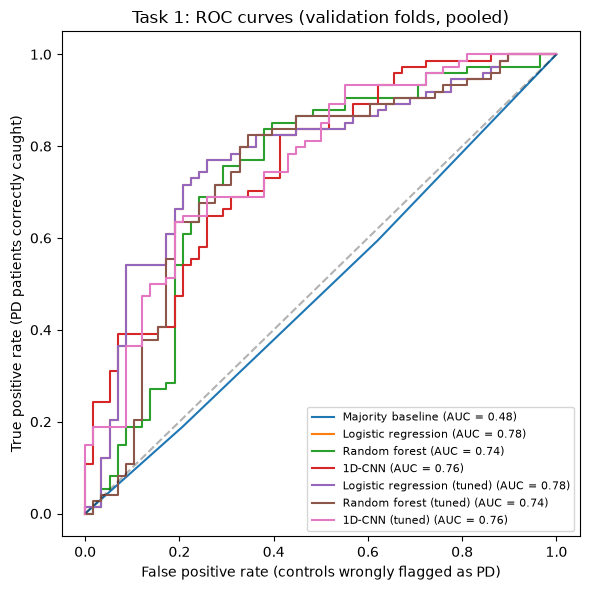

In [4]:
# visual representation of results for task 1 (roc curves)
fig, ax = plt.subplots(figsize=(6, 6))
for model_name, df in task1_predictions.items():
    fpr, tpr, _ = roc_curve(df.y_true, df.y_prob)
    ax.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc_score(df.y_true, df.y_prob):.2f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
ax.set_xlabel("False positive rate (controls wrongly flagged as PD)")
ax.set_ylabel("True positive rate (PD patients correctly caught)")
ax.set_title("Task 1: ROC curves (validation folds, pooled)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task1_roc_curves.png", dpi=150)
plt.show()

In [21]:
# since logreg is the best model, elaborate on the metrics specific to it
log_reg = task1_predictions['Logistic regression']
cm = confusion_matrix(log_reg.y_true, log_reg.y_pred)
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
tpr = tp / (tp+fn)
tnr = tn / (fp+tn)

table = pd.DataFrame(
    cm,
    index=["Actual: Healthy", "Actual: PD"],
    columns=["Predicted: Healthy", "Predicted: PD"],
)
table["Rate"] = [f"FPR = {tn}/{fp+tn} = {tnr:.3f}", f"TPR = {tp}/{tp+fn} = {tpr:.3f}"]
display(table)

# decent values, however 1/4 patients still missed

,Predicted: Healthy,Predicted: PD,Rate
Actual: Healthy,43,15,FPR = 43/58 = 0.741
Actual: PD,18,56,TPR = 56/74 = 0.757


## Task 2 results

Comparison and evaluation of the classical models (multiple linear regression, random forests) and the deep learning model (1D-CNN) against the mean baseline. 

In [6]:
def load_predictions(folder, prefix, n_folds=5):
    paths = [folder / f"{prefix}_val_fold{k}.csv"
        for k in range(1, n_folds + 1)]
    return pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)

def regression_metrics(df, target):
    actual = df[f"actual_{target}"]
    predicted = df[f"predicted_{target}"]
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

#### UPDRSM Results

In [7]:
# load predictions for every model
updrsm_models = {
    "Mean baseline": "mean_baseline",
    "MLR": "linear_regression",
    "Random forest": "random_forest",
    "1D-CNN": "cnn",
    "Random forest (tuned)": "random_forest_tuned",
    "1D-CNN (tuned)": "cnn_tuned"
}

updrsm_predictions = {}

for name, prefix in updrsm_models.items():
    df = load_predictions(TASK2_DIR, prefix)
    updrsm_predictions[name] = df

print("UPDRSM models loaded:", list(updrsm_predictions))


UPDRSM models loaded: ['Mean baseline', 'MLR', 'Random forest', '1D-CNN', 'Random forest (tuned)', '1D-CNN (tuned)']


In [8]:
# calculate MAE and RMSE for each model
updrsm_results = []
for name, df in updrsm_predictions.items():
    scores = regression_metrics(df, "UPDRSM")
    updrsm_results.append({
        "Model": name,
        "N": len(df),
        **scores
    })
updrsm_summary = pd.DataFrame(updrsm_results)

# calculate relative performance to baseline 
baseline = updrsm_summary.loc[
    updrsm_summary["Model"] == "Mean baseline"
].iloc[0]

for metric in ["MAE", "RMSE"]:

    updrsm_summary[f"{metric} improvement (%)"] = (
        (baseline[metric] - updrsm_summary[metric])
        / baseline[metric] * 100
    )

updrsm_summary = updrsm_summary.sort_values("RMSE")

display(updrsm_summary.round(3))

updrsm_summary.to_csv(
    RESULTS_DIR / "updrsm_summary.csv",
    index=False
)

,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,Mean baseline,72,6.503,8.050,0.000,0.000
1,MLR,72,6.506,8.173,-0.047,-1.535
4,Random forest (tuned),72,6.423,8.197,1.226,-1.830
2,Random forest,72,6.609,8.393,-1.638,-4.257
3,1D-CNN,72,7.114,8.768,-9.404,-8.927
5,1D-CNN (tuned),72,7.114,8.768,-9.404,-8.927


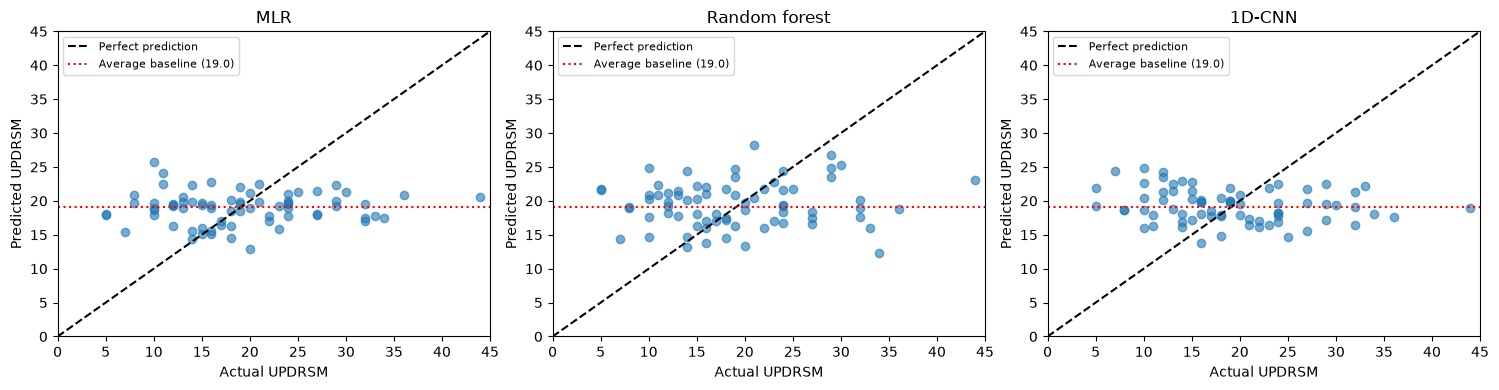

In [9]:
# model plots
models_to_plot = [
    "MLR",
    "Random forest",
    "1D-CNN"
]

# compare to baseline 
baseline_mean = updrsm_predictions["Mean baseline"]["predicted_UPDRSM"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, models_to_plot):
    df = updrsm_predictions[name]
    ax.scatter(
        df["actual_UPDRSM"],
        df["predicted_UPDRSM"],
        alpha=0.6
    )
    
    # 45 degree line indicates perfect prediction 
    ax.plot([0, 45], [0, 45], "k--", label="Perfect prediction")

    # horizontal reference is the average CV baseline
    ax.axhline(
        baseline_mean,
        color="red",
        linestyle=":",
        label=f"Average baseline ({baseline_mean:.1f})"
    )

    ax.set(
        title=name,
        xlabel="Actual UPDRSM",
        ylabel="Predicted UPDRSM",
        xlim=(0, 45),
        ylim=(0, 45)
    )

    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "updrsm_predictions.png", dpi=200)
plt.show()

In [10]:
# compare by severity 
severity_results = []

for name, df in updrsm_predictions.items():
    df = df.copy()
    
    # split by ranges
    df["Severity"] = pd.cut(
        df["actual_UPDRSM"],
        bins=[-np.inf, 15, 25, np.inf],
        labels=["Lower", "Middle", "Higher"]
    )

    df["Error"] = (
        df["actual_UPDRSM"] - df["predicted_UPDRSM"]
    )

    for severity, part in df.groupby(
        "Severity", observed=True
    ):

        severity_results.append({
            "Model": name,
            "Severity": severity,
            "N": len(part),
            "MAE": part["Error"].abs().mean(),
            "Mean signed error": part["Error"].mean()
        })

updrsm_severity = pd.DataFrame(severity_results)

display(updrsm_severity.round(2))

,Model,Severity,N,MAE,Mean signed error
0,Mean baseline,Lower,27,7.75,-7.75
1,Mean baseline,Middle,31,2.68,1.10
2,Mean baseline,Higher,14,12.56,12.56
3,MLR,Lower,27,7.69,-7.69
4,MLR,Middle,31,2.93,1.45
5,MLR,Higher,14,12.14,12.14
6,Random forest,Lower,27,8.10,-8.04
7,Random forest,Middle,31,3.09,0.72
8,Random forest,Higher,14,11.52,11.52
9,1D-CNN,Lower,27,8.86,-8.86


#### HoehnYahr results

In [11]:
# load predictions
hy_models = {
    "Mean baseline": "mean_baseline_HoehnYahr",
    "MLR": "linear_regression_HoehnYahr",
    "Random forest (tuned)": "random_forest_HoehnYahr",
    "1D-CNN (tuned)": "cnn_HoehnYahr"
}

hy_predictions = {}

for name, prefix in hy_models.items():
    df = load_predictions(TASK2_DIR, prefix)
    hy_predictions[name] = df


In [12]:
# calculate hy regression performance.
hy_results = []

for name, df in hy_predictions.items():
    scores = regression_metrics(df, "HoehnYahr")
    hy_results.append({
        "Model": name,
        "N": len(df),
        **scores
    })

hy_summary = pd.DataFrame(hy_results)
baseline = hy_summary.loc[
    hy_summary["Model"] == "Mean baseline"
].iloc[0]
for metric in ["MAE", "RMSE"]:

    hy_summary[f"{metric} improvement (%)"] = (
        (baseline[metric] - hy_summary[metric])
        / baseline[metric] * 100
    )

hy_summary = hy_summary.sort_values("RMSE")
display(hy_summary.round(3))
hy_summary.to_csv(
    RESULTS_DIR / "hoehnyahr_summary.csv",
    index=False)

,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
1,MLR,72,0.237,0.295,21.297,12.517
2,Random forest (tuned),72,0.244,0.302,18.878,10.342
0,Mean baseline,72,0.301,0.337,0.000,0.000
3,1D-CNN (tuned),72,0.355,0.447,-17.808,-32.676


In [13]:
# to uncover whether hy predictions are within 0.5 and 1 stage away from the actual
hy_stage_results = []

for model_name, df in hy_predictions.items():

    actual = df["actual_HoehnYahr"].to_numpy()
    predicted = df["predicted_HoehnYahr"].to_numpy()

    absolute_error = np.abs(actual - predicted)

    hy_stage_results.append({
        "Model": model_name,
        "MAE": absolute_error.mean(),
        "Within 0.5 stage (%)": 100 * np.mean(
            absolute_error <= 0.5
        ),
        "Within 1 stage (%)": 100 * np.mean(
            absolute_error <= 1.0
        )
    })

display(pd.DataFrame(hy_stage_results).round(2))

,Model,MAE,Within 0.5 stage (%),Within 1 stage (%)
0,Mean baseline,0.30,90.28,100.00
1,MLR,0.24,91.67,100.00
2,Random forest (tuned),0.24,91.67,100.00
3,1D-CNN (tuned),0.35,79.17,95.83


#### UPDRS prediction

In [14]:
updrs_models = {
    "Mean baseline": "mean_baseline_UPDRS",
    "MLR": "linear_regression_UPDRS",
    "Random forest (tuned)": "random_forest_UPDRS",
    "1D-CNN (tuned)": "cnn_UPDRS"
}

updrs_predictions = {}

for name, prefix in updrs_models.items():
    df = load_predictions(TASK2_DIR, prefix)
    updrs_predictions[name] = df

print("UPDRS models loaded:", list(updrs_predictions))

UPDRS models loaded: ['Mean baseline', 'MLR', 'Random forest (tuned)', '1D-CNN (tuned)']


In [15]:
updrs_results = []

for name, df in updrs_predictions.items():
    scores = regression_metrics(df, "UPDRS")
    updrs_results.append({
        "Model": name,
        "N": len(df),
        **scores
    })

updrs_summary = pd.DataFrame(updrs_results)

baseline = updrs_summary.loc[updrs_summary["Model"] == "Mean baseline"].iloc[0]

# calculate percentage improvement from baseline
for metric in ["MAE", "RMSE"]:

    updrs_summary[f"{metric} improvement (%)"] = (
        (baseline[metric] - updrs_summary[metric])
        / baseline[metric] * 100
    )

updrs_summary = updrs_summary.sort_values("RMSE")

display(updrs_summary.round(3))

updrs_summary.to_csv(
    RESULTS_DIR / "updrs_summary.csv",
    index=False
)

,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,Mean baseline,72,9.881,12.253,0.000,0.000
2,Random forest (tuned),72,10.472,12.549,-5.979,-2.419
1,MLR,72,10.109,12.647,-2.307,-3.219
3,1D-CNN (tuned),72,10.357,13.029,-4.818,-6.336


In [16]:
# final comparison
comparison = pd.concat([
    updrsm_summary.assign(Target="UPDRSM"),
    hy_summary.assign(Target="HoehnYahr"),
    updrs_summary.assign(Target="UPDRS")
], ignore_index=True)

# Show the same columns for both outcomes.
comparison = comparison[[
    "Target",
    "Model",
    "N",
    "MAE",
    "RMSE",
    "MAE improvement (%)",
    "RMSE improvement (%)"
]]

display(comparison.round(3))

comparison.to_csv(
    RESULTS_DIR / "severity_target_comparison.csv",
    index=False
)

,Target,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,UPDRSM,Mean baseline,72,6.503,8.050,0.000,0.000
1,UPDRSM,MLR,72,6.506,8.173,-0.047,-1.535
2,UPDRSM,Random forest (tuned),72,6.423,8.197,1.226,-1.830
3,UPDRSM,Random forest,72,6.609,8.393,-1.638,-4.257
4,UPDRSM,1D-CNN,72,7.114,8.768,-9.404,-8.927
5,UPDRSM,1D-CNN (tuned),72,7.114,8.768,-9.404,-8.927
6,HoehnYahr,MLR,72,0.237,0.295,21.297,12.517
7,HoehnYahr,Random forest (tuned),72,0.244,0.302,18.878,10.342
8,HoehnYahr,Mean baseline,72,0.301,0.337,0.000,0.000
9,HoehnYahr,1D-CNN (tuned),72,0.355,0.447,-17.808,-32.676


## Test set results
Final models are trained on all cross-validation subjects and scored once on the held-out test subjects (33 for Task 1, 19 for Task 2). Hence performed training, cross validation and now testing.

In [17]:
# Task 1
task1_test = []
for model_name, prefix in task1_models.items():
    path = TASK1_DIR / f"{prefix}_test.csv"
    if path.exists():
        df = pd.read_csv(path)
        task1_test.append({"Model": model_name,
                           "Accuracy": accuracy_score(df["y_true"], df["y_pred"]),
                           "F1": f1_score(df["y_true"], df["y_pred"]),
                           "ROC-AUC": roc_auc_score(df["y_true"], df["y_prob"])})
task1_test = pd.DataFrame(task1_test)
display(task1_test.round(3))
task1_test.round(4).to_csv(RESULTS_DIR / "task1_test_summary.csv", index=False)

# Task 2
task2_test = []
for target, models in [("UPDRSM", updrsm_models), ("HoehnYahr", hy_models), ("UPDRS", updrs_models)]:
    for model_name, prefix in models.items():
        path = TASK2_DIR / f"{prefix}_test.csv"
        if path.exists():
            df = pd.read_csv(path)
            task2_test.append({"Target": target, "Model": model_name,**regression_metrics(df, target)})
task2_test = pd.DataFrame(task2_test)
display(task2_test.round(3))
task2_test.round(4).to_csv(RESULTS_DIR / "task2_test_summary.csv", index=False)

,Model,Accuracy,F1,ROC-AUC
0,Majority baseline,0.576,0.731,0.500
1,Logistic regression,0.667,0.703,0.707
2,Random forest,0.606,0.683,0.680
3,1D-CNN,0.818,0.824,0.838
4,Logistic regression (tuned),0.667,0.703,0.707
5,Random forest (tuned),0.697,0.750,0.759
6,1D-CNN (tuned),0.788,0.800,0.786


,Target,Model,MAE,RMSE
0,UPDRSM,Mean baseline,5.096,6.259
1,UPDRSM,MLR,5.249,6.069
2,UPDRSM,Random forest,4.454,5.419
3,UPDRSM,1D-CNN,5.036,5.970
4,UPDRSM,Random forest (tuned),4.765,5.585
5,UPDRSM,1D-CNN (tuned),5.036,5.970
6,HoehnYahr,Mean baseline,0.331,0.376
7,HoehnYahr,MLR,0.269,0.334
8,HoehnYahr,Random forest (tuned),0.260,0.331
9,HoehnYahr,1D-CNN (tuned),0.380,0.484


For task 1, we previously established that logreg was the best on the validation set. Here, CNN beats logreg. However, because the test set is only 33 subjects (smaller pool), we based our best model on the validation set and treated the test set as a final test. Thats something which is unavoidable given the small dataset.

For task 2, rf has the lowest MAE for all three targets. On validation, only H&Y beats the mean baseline. Because the test set is so small, the test gains for UPDRSM and UPDRS are uncertain.